# Notebook 12: Real Time vs Imaginary Time

**Goal:** Run one Hamiltonian two ways: in real time, which gives Barandes's indivisible process Γ, and in imaginary time
(the "Wick rotation" behind Euclidean quantum field theory), which gives an ordinary Markov chain on the same configurations. Then find out what
separates them, and why fermions are the hard case.

By the end of this notebook you will be able to:
- Show that the real-time Γ is indivisible (for almost every pair of times tested) while the imaginary-time process, after a ground-state
  transform, is an exact Markov semigroup that relaxes to $\psi_0^2$ at the energy gap
- Contrast how the two processes start: real-time transitions grow as $t^2$ with no rate, imaginary-time transitions have rates
- Show that Γ itself cannot be Wick-rotated, and that for real $H$ it cannot tell $H$ from $-H$ while imaginary time can
  (in general $\Gamma(H) = \Gamma(-H^*)$; on bipartite lattices with no potential Γ is blind to the sign of $H$ even with a flux)
- Read the "sign problem" as a gauge question: the rephasings that leave Γ unchanged must make $H$ stoquastic
- See that two fermions on a chain behave exactly like hard-core bosons, and that the difference, and the sign problem, can appear only when
  particles can exchange around a loop

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

---
> ### 📓 Annotated study copy
>
> Study copy of `12_wick_rotation.ipynb`. Same code and outputs, plus sections marked
> **📖 In depth**, **🔍 Reading the code** and **🔭 Looking ahead**.
>
> Written 2026-10-24 from the Wick-rotation spike (`notes/wick-rotation-spike-2026-10-24.md`), item 2 of the textbook backlog
> (`notes/textbook-concepts-backlog-2026-10-24.md`), prompted by Peskin & Schroeder §9.3. The question: *Euclidean field theory turns quantum
> mechanics into classical statistical mechanics; how does that classical process relate to Barandes's indivisible one, and why are fermions hard?*
> Short answer: they are opposite processes on the same configurations, Γ itself does not survive the rotation, and the obstacle for fermions is a
> sign that appears only when particles exchange around a loop.
>
> **Prior work (checked 2026-10-29).** The pieces are known: the ground-state transform, the sign problem as a stoquastic-gauge question
> (arXiv:1906.02309, arXiv:2508.14382), the fermion sign around a ring (arXiv:1812.05080), and $\Gamma(H) = \Gamma(-H^*)$, which is elementary
> (Barandes notes after his eq. 89, Paper 3 §4.1, that complex conjugation is "just a change of phases"). Details in the 🔭 cell at the end.
>
> Right after this banner: a summary of what Γ explains here and what it doesn't.
---

### 📖 In depth: what Γ explains about the Wick rotation, and what it doesn't

**What Γ explains**
- **Why the Euclidean picture is not the ISP picture.** Same configurations and the same $H$, but one process is a Markov semigroup and the other is
  indivisible (section 1). The Euclidean chain is a different stochastic process, not a hidden-variable account of the real-time one.
- **Why real-time histories have no probabilities.** Transitions start as $t^2$, with no rate to build path weights from (section 2).
- **Which part of the sign problem is "unphysical".** Signs that a gauge can move are invisible to Γ; only loop products (frustration, flux) remain
  (sections 4 and 5). Γ itself sees those loop products only partly (see the 📖 cell after section 4).
- **That fermions are fine in real time.** The fermion configuration process is well defined; its Γ is gauge-invariant (section 5).

**What Γ does not explain**
- **The Wick rotation itself.** It is an analytic continuation of amplitudes; Γ is not analytic in $t$ (it contains a complex conjugate), and continuing it
  gives a non-stochastic matrix (section 3).
- **Which state is the ground state.** For real $H$, and on bipartite lattices with no potential even with a flux, Γ is blind to the sign of $H$
  (in general it cannot tell $H$ from $-H^*$); the Euclidean chain is not.
  Energy ordering is Hilbert-space information.
- **Whether the sign problem can be solved some other way.** The gauge search here uses only $\pm1$ signs on configurations; other bases are outside Γ's scope.

**Net.** The rotation lives in the amplitudes; what Γ adds is a sharp statement of what the two pictures share (configurations, gauge freedom) and
what they do not (divisibility, rates, the sign of energy).

<!-- expansion:12:before-you-start -->
### 🧭 Before you start

**What this notebook is for.** Quantum field theory has a famous trick: rotate time into the imaginary direction and the quantum theory becomes classical
statistical mechanics, with an ordinary random process underneath. Barandes says quantum theory already *is* a random process, just an indivisible one.
This notebook puts the two side by side on the smallest possible example and asks how they relate, and why fermions (electrons, quarks) are the case where
the imaginary-time trick breaks.

**Prerequisites.**
- Notebook 03: the derived intermediate $\Gamma(t)\Gamma(t')^{-1}$ and indivisibility.
- Notebooks 03 and 04: re-phasing the amplitudes changes no prediction (the gauge freedom of Γ).
- Notebook 07: the agility and the short-time behaviour of Γ.
- Notebook 10: the slow ($t^2$) start, and the negative-mass test.
- No quantum field theory is needed; the 📚 cells summarize what Peskin & Schroeder say.

**How to run it.** From the `notebooks/` folder, *Kernel > Restart & Run All*. The first code cell imports from `isp/wick.py`, so `isp/` must sit next to
`notebooks/`. Needs numpy, scipy and matplotlib. It runs in a few seconds; the gauge searches are exhaustive, which is why the lattices are small.

**Search-engineer framing.** A random walk on a link graph with rates (PageRank-style) settles into a stationary ranking. This notebook builds such a walk from a
quantum Hamiltonian, and contrasts it with the indivisible process the same Hamiltonian generates in real time.


<!-- expansion:12:glossary -->
### 📘 Glossary

- **Configuration.** A site (one particle) or a pair of occupied sites (two particles).
- **Real time / Γ.** $\Gamma(t) = |e^{-iHt}|^2$: Barandes's indivisible process.
- **Imaginary time, Wick rotation.** Replacing $t$ by $-i\tau$, so $e^{-iHt}$ becomes $e^{-H\tau}$.
- **Ground state $\psi_0$, energy $E_0$.** The lowest-energy eigenvector of $H$. **Gap.** $E_1 - E_0$.
- **Ground-state transform.** $P_{ij}(\tau) = \psi_0(i)[e^{-(H-E_0)\tau}]_{ij}/\psi_0(j)$: turns $e^{-H\tau}$ into a matrix whose columns sum to 1.
- **Markov semigroup.** A family of stochastic matrices with $P(a+b) = P(b)P(a)$. **Rate matrix (generator) $L$.** $P(\tau) = e^{L\tau}$; off-diagonal entries are jump rates.
- **Feynman–Kac.** The statement that imaginary-time amplitudes are expectations over the histories of a Markov process.
- **Stoquastic.** A real Hamiltonian whose off-diagonal entries are all ≤ 0; then $e^{-H\tau}$ has no negative entries.
- **Gauge.** $H \mapsto DHD$ with $D$ diagonal (here $\pm1$). Leaves Γ unchanged: a special case of Barandes's Schur–Hadamard gauge (Paper 3, §3.2, eqs. 29–30).
- **Loop product.** The product of the bond signs around a closed loop. Unchanged by any gauge.
- **Frustrated loop.** A loop whose product differs from the stoquastic one; no gauge fixes it.
- **Sign problem.** No gauge makes $H$ stoquastic, so imaginary time has no Markov representation in these configurations.
- **Hard-core bosons.** Particles that cannot share a site but carry no exchange sign. **Spinless fermions.** The same, plus a $-1$ per particle passed (**Jordan–Wigner sign**).


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from isp.wick import (real_gamma, euclidean_markov, negative_mass, is_stoquastic, stoquastic_gauge,
                      hopping_hamiltonian, two_particle_hamiltonian)

### 📖 In depth: the Wick rotation, in plain words

- **The trick.** Quantum dynamics multiplies by $e^{-iHt}$. Replace time $t$ by an imaginary time $-i\tau$ and that becomes $e^{-H\tau}$, the same kind of factor
  that appears in statistical mechanics as a Boltzmann weight. Peskin & Schroeder use this to turn a quantum field into a classical random field,
  "precisely the partition function" of a statistical system.
- **Why it matters here.** Statistical mechanics has an honest Markov process behind it. If quantum mechanics is "really" an indivisible process (Barandes),
  how does that sit next to the Markov process imaginary time produces?
- **Answer of this notebook.** They are two different processes on the same configurations. The imaginary-time one is Markov, has rates and settles down.
  The real-time one is indivisible, has no rates and never settles. Γ does not turn into the Markov chain under the rotation; only the amplitudes do.
- **For a search engineer.** Think of the same click graph run two ways: as a random walk with transition rates (PageRank-like, settles to a stationary
  ranking), versus a process whose step-to-step probabilities cannot be chained. Same nodes, same edges, opposite behaviour.

## 1. One Hamiltonian, Two Processes

A particle hops between 6 sites in a line, with a random potential. The configurations are the sites.

- **Real time.** $\Gamma(t) = |e^{-iHt}|^2$, as in every notebook so far.
- **Imaginary time.** Replace $t$ by $-i\tau$: $e^{-iHt}$ becomes $e^{-H\tau}$, a matrix of real, non-negative numbers for this $H$, but not a stochastic matrix.
  The standard fix is the **ground-state transform**

$$P_{ij}(\tau) = \frac{\psi_0(i)\,\big[e^{-(H - E_0)\tau}\big]_{ij}}{\psi_0(j)},$$

where $\psi_0$ is the ground state and $E_0$ its energy. Test both for divisibility.

<!-- expansion:12:books-peskin -->
### 📚 From the books: Peskin & Schroeder on imaginary time

- **The real-time path integral** (Peskin & Schroeder §9.1, printed p. 276): "When a process can take place in more than one way, its total amplitude is the
  coherent sum of the amplitudes for each way." Amplitudes per history, not probabilities.
- **The rotation** (§9.3, printed pp. 292–293): the generating functional "is reminiscent of the partition function of statistical mechanics. It has the same general structure
  of an integral over all possible configurations of an exponential statistical weight." After the Wick rotation, "$Z[J]$ is precisely the partition function describing the
  statistical mechanics of a macroscopic system".
- **Fermions** (§9.5, printed p. 299): anticommuting (Grassmann) numbers are defined by "algebraic rules for manipulating them. These rules are formal and might seem ad hoc.
  We will justify them by showing that they lead to the familiar quantum theory of the Dirac equation." Grassmann variables have no numerical values, so a fermion
  field has no ordinary "configuration" to put a probability on. That is the textbook form of the difficulty section 5 makes concrete.

Barandes (Correspondence §3.5) notes that "quantum fields are conceptually distinct from Schrödinger waves", and points to Weinberg for why fields are needed. The papers on
disk do not discuss imaginary time or fermion configurations.


6 sites, hopping -1, random potential;  energy gap E1 - E0 = 1.0997

Real time, Γ(t) = |exp(-iHt)|²:
  (0.3, 0.6): negative mass of the derived intermediate = 1.8e-05
  (1.0, 1.5): negative mass of the derived intermediate = 8.5e-01
  (2.0, 3.0): negative mass of the derived intermediate = 5.9e+00
  indivisible for 98% of the pairs (t', t' + 0.3), t' from 0.1 to 5;  divisible only at t' = [0.1]

Imaginary time, ground-state transform P(τ):
  smallest entry of P(0.4): 1.50e-05   largest column-sum error: 4.4e-16
  P(1.1) − P(0.7)·P(0.4): 8.6e-16   (a Markov semigroup)
  P(τ)·ψ0² − ψ0²: 2.8e-16   (ψ0² is stationary)


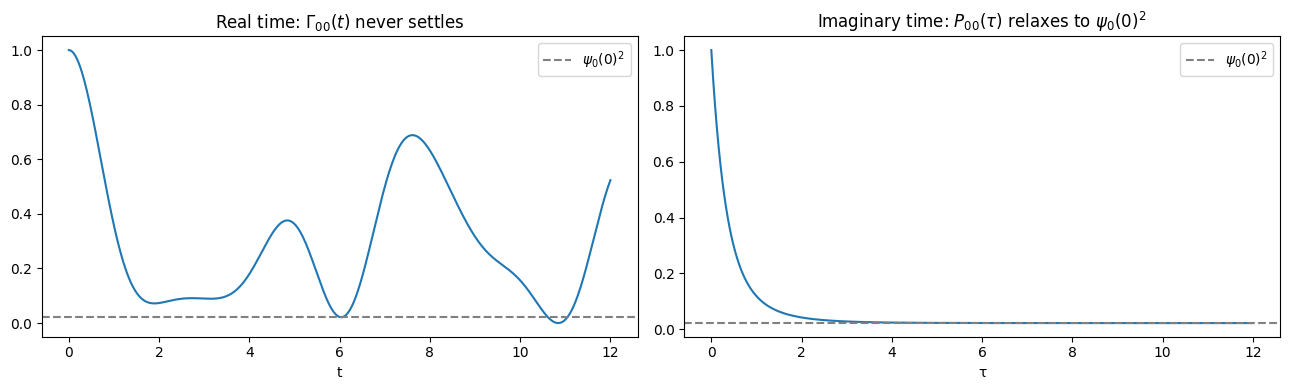

relaxation per unit τ: 0.3330   e^(−gap) = 0.3330


In [2]:
rng = np.random.default_rng(0)
V = rng.uniform(-1, 1, 6)
H = hopping_hamiltonian(6, potential=V)
E = np.linalg.eigvalsh(H)
gap = E[1] - E[0]
print(f"6 sites, hopping -1, random potential;  energy gap E1 - E0 = {gap:.4f}")

print("\nReal time, Γ(t) = |exp(-iHt)|²:")
for t1, t2 in [(0.3, 0.6), (1.0, 1.5), (2.0, 3.0)]:
    D = real_gamma(H, t2) @ np.linalg.inv(real_gamma(H, t1))
    print(f"  ({t1}, {t2}): negative mass of the derived intermediate = {negative_mass(D):.1e}")
grid = np.linspace(0.1, 5, 50)
neg = [negative_mass(real_gamma(H, a + 0.3) @ np.linalg.inv(real_gamma(H, a))) for a in grid]
print(f"  indivisible for {np.mean(np.array(neg) > 1e-9):.0%} of the pairs (t', t' + 0.3), t' from 0.1 to 5;"
      f"  divisible only at t' = {grid[np.array(neg) <= 1e-9].round(2)}")

print("\nImaginary time, ground-state transform P(τ):")
Pa, psi = euclidean_markov(H, 0.4)
Pb, _ = euclidean_markov(H, 0.7)
Pab, _ = euclidean_markov(H, 1.1)
print(f"  smallest entry of P(0.4): {Pa.min():.2e}   largest column-sum error: {abs(Pa.sum(axis=0) - 1).max():.1e}")
print(f"  P(1.1) − P(0.7)·P(0.4): {abs(Pab - Pb @ Pa).max():.1e}   (a Markov semigroup)")
print(f"  P(τ)·ψ0² − ψ0²: {abs(Pa @ psi ** 2 - psi ** 2).max():.1e}   (ψ0² is stationary)")

ts = np.linspace(0, 12, 600)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ts, [real_gamma(H, t)[0, 0] for t in ts])
ax[0].axhline(psi[0] ** 2, color='gray', ls='--', label='$\\psi_0(0)^2$')
ax[0].set_title('Real time: $\\Gamma_{00}(t)$ never settles'); ax[0].set_xlabel('t'); ax[0].legend()
ax[1].plot(ts, [euclidean_markov(H, t)[0][0, 0] for t in ts])
ax[1].axhline(psi[0] ** 2, color='gray', ls='--', label='$\\psi_0(0)^2$')
ax[1].set_title('Imaginary time: $P_{00}(\\tau)$ relaxes to $\\psi_0(0)^2$'); ax[1].set_xlabel('τ'); ax[1].legend()
plt.tight_layout(); plt.show()

P5, _ = euclidean_markov(H, 5.0)
P6, _ = euclidean_markov(H, 6.0)
stat = np.outer(psi ** 2, np.ones(6))
print(f"relaxation per unit τ: {abs(P6 - stat).max() / abs(P5 - stat).max():.4f}   e^(−gap) = {np.exp(-gap):.4f}")

### 🔍 Reading the code

- **`hopping_hamiltonian(6, potential=V)`** builds the 6×6 matrix: $-1$ between neighbouring sites, the random potential on the diagonal.
- **`real_gamma(H, t)`** is $|e^{-iHt}|^2$ entry by entry.
- **`euclidean_markov(H, tau)`** returns the ground-state transform $P(\tau)$ and the ground state $\psi_0$ (sign chosen positive).
- **Negative mass** is the largest total negative weight in a column of the derived intermediate $\Gamma(t)\Gamma(t')^{-1}$: zero when a stochastic intermediate exists
  (notebook 10).
- **The relaxation line** compares how much $P(\tau)$ moves toward its stationary state in one unit of τ with $e^{-\text{gap}}$.

### 📖 In depth: why the ground-state transform is Markov

- **Columns sum to 1.** $\sum_i \psi_0(i)\,[e^{-(H-E_0)\tau}]_{ij} = \psi_0(j)$, because $\psi_0$ is an eigenvector with eigenvalue $E_0$ (and $H$ is symmetric). Dividing by $\psi_0(j)$ gives 1.
- **Semigroup.** $e^{-(H-E_0)(a+b)} = e^{-(H-E_0)b}e^{-(H-E_0)a}$, and the $\psi_0$ factors in the middle cancel. So $P(a+b) = P(b)P(a)$ exactly: divisible at every time, with the
  intermediate equal to $P(b)$ itself.
- **Non-negative.** For stoquastic $H$, $e^{-H\tau}$ has no negative entries (the Perron–Frobenius setting), and $\psi_0 > 0$.
- **Stationary state and relaxation.** $\psi_0^2$ is stationary; the other eigenvalues are $e^{-(E_n - E_0)\tau}$, so the slowest relaxation is $e^{-\text{gap}\cdot\tau}$.

None of this uses Γ. The real-time process has the same configurations and the same $H$, yet its derived intermediates go negative within a fraction of a time unit.

<!-- expansion:12:recap-1 -->
### 📝 Recap: section 1

- Same six sites, same $H$. Real time: Γ indivisible for 98% of the pairs tested. Imaginary time: an exact Markov semigroup.
- The imaginary-time chain is stationary at $\psi_0^2$ and relaxes at the gap; the real-time $\Gamma_{00}$ keeps oscillating.
- So the Euclidean process is a different process on the same configurations, not a divisible version of Γ.


## 2. Rates, and Path Probabilities

How do the two processes start? For a short time, compare the probability of moving from site 0 to site 1.

<!-- expansion:12:derive-short-time -->
### 🧮 Worked derivation: t² versus t

**Real time.** $e^{-iHt} \approx 1 - iHt$, so for $i \neq j$ the amplitude is $-iH_{ij}t$ and $\Gamma_{ij}(t) \approx |H_{ij}|^2 t^2$. Summed over $i \neq j$ this is $\nu_j^2 t^2$, notebook 07's agility.

**Imaginary time.** $e^{-(H-E_0)\tau} \approx 1 - (H - E_0)\tau$, so for $i \neq j$, $P_{ij}(\tau) \approx -H_{ij}\tau\,\psi_0(i)/\psi_0(j)$, which is positive for stoquastic $H$. That is a **rate**:
$L_{ij} = -H_{ij}\psi_0(i)/\psi_0(j)$. The diagonal $L_{jj} = -(H_{jj} - E_0)$ makes each column of $L$ sum to zero, by the same eigenvector identity that makes $P$'s columns sum to 1.

The rates send the walker toward sites where $\psi_0$ is large ($\psi_0(i)/\psi_0(j) > 1$): the chain is steered toward the ground-state distribution, which it then keeps.


In [3]:
print("short-time move 0 → 1:")
for t in [1e-2, 1e-3]:
    G = real_gamma(H, t)
    P, _ = euclidean_markov(H, t)
    print(f"  t = {t}:  real Γ = {G[1, 0]:.3e}  (|H10|²t² = {abs(H[1, 0]) ** 2 * t * t:.3e})"
          f"    imaginary P = {P[1, 0]:.3e}  (t|H10|ψ0(1)/ψ0(0) = {t * abs(H[1, 0]) * psi[1] / psi[0]:.3e})")

L = -(psi[:, None] * (H - E[0] * np.eye(6)) / psi[None, :])
print("\nimaginary-time rate matrix L = −ψ0 (H − E0) ψ0⁻¹ (off-diagonal = jump rates):")
print(np.round(L, 3) + 0.0)   # + 0.0 turns -0.0 into 0.0
print(f"off-diagonal entries all ≥ 0: {np.all(L - np.diag(np.diag(L)) >= -1e-12)};  columns sum to 0: {np.allclose(L.sum(axis=0), 0)}")

short-time move 0 → 1:
  t = 0.01:  real Γ = 9.999e-05  (|H10|²t² = 1.000e-04)    imaginary P = 2.651e-02  (t|H10|ψ0(1)/ψ0(0) = 2.714e-02)
  t = 0.001:  real Γ = 1.000e-06  (|H10|²t² = 1.000e-06)    imaginary P = 2.707e-03  (t|H10|ψ0(1)/ψ0(0) = 2.714e-03)

imaginary-time rate matrix L = −ψ0 (H − E0) ψ0⁻¹ (off-diagonal = jump rates):
[[-2.714  0.369  0.     0.     0.     0.   ]
 [ 2.714 -1.979  0.621  0.     0.     0.   ]
 [ 0.     1.611 -1.522  1.11   0.     0.   ]
 [ 0.     0.     0.901 -1.473  2.76   0.   ]
 [ 0.     0.     0.     0.362 -3.066  3.265]
 [ 0.     0.     0.     0.     0.306 -3.265]]
off-diagonal entries all ≥ 0: True;  columns sum to 0: True


### 📖 In depth: why rates matter

A Markov chain is built from rates: in a short time $dt$ the chance to jump from $j$ to $i$ is $L_{ij}\,dt$. Chain many short steps and every history gets a probability, the
product of its steps. That is the Feynman–Kac picture of imaginary time.

Real-time Γ starts as $|H_{ij}|^2t^2$: the chance of a jump in time $dt$ is of order $dt^2$, so if $\Gamma(dt)$ were chained as a Markov step, jumps would vanish as $dt \to 0$ (Zeno),
and Γ cannot be built from rates. This is notebook 10's slow start
and notebook 11's Zeno freezing, now as a structural fact: there is no rate to build history probabilities from. Peskin's real-time path integral is "the coherent sum of the
amplitudes for each way": amplitudes per history, not probabilities.

<!-- expansion:12:recap-2 -->
### 📝 Recap: section 2

- Real-time transitions start as $|H_{ij}|^2t^2$: no rate.
- Imaginary-time transitions start as $t\,|H_{ij}|\,\psi_0(i)/\psi_0(j)$: rates, collected in the generator $L$ (non-negative off-diagonals, zero column sums).
- Rates give every history a probability (Feynman–Kac); real time gives histories only amplitudes.


## 3. Γ Itself Does Not Wick-Rotate

For a real $H$, $\Gamma(t) = e^{-iHt} \circ e^{+iHt}$, where ∘ multiplies entry by entry. Continuing $t \to -i\tau$ in that formula gives $e^{-H\tau} \circ e^{+H\tau}$.
Is that a transition matrix? And a second test: for real $H$, Γ cannot distinguish $H$ from $-H$. Can imaginary time?

The "real" matters. For any $H$, $\overline{e^{-iHt}} = e^{-i(-H^*)t}$, so $\Gamma(H) = \Gamma(-H^*)$. This is elementary ($|\bar z| = |z|$); Barandes notes, right after his
anti-unitary symmetry condition (Paper 3, §4.1, eq. 89, p. 23), that complex conjugation is "just a change of phases". Γ is also unchanged when the configurations are
re-phased (section 4). So Γ is blind to the sign of $H$ whenever $H^*$ can be re-phased into $H$ (for example $H$ real, or a ring with flux 0 or π), and also whenever
$-H$ can be re-phased into $H$: on a bipartite lattice with no potential (a chain, an even ring), flipping the sign of every other site turns $H$ into $-H$, whatever the flux.
On the odd ring of 5 with flux π/2 neither holds, and Γ does tell $H$ from $-H$. The cell checks that ring and an even ring with the same flux.

<!-- expansion:12:howto-3 -->
### 🧭 How to use the next cell

- `expm(-H * tau) * expm(H * tau)` multiplies two matrices **entry by entry** (`*`, not `@`). For real $H$ this is what $|e^{-iHt}|^2$ becomes when $t \to -i\tau$.
- Watch two numbers per line: how far the column sums are from 1 (tiny) and the range of entries (far outside $[0, 1]$).
- The second part runs the Euclidean chain for $H$ and for $-H$ and prints both ground-state distributions. Real-time Γ is identical for the two.
- **Things to try:** use a smaller τ (0.1). The entries stay closer to $[0,1]$ but still go negative.


In [4]:
for tau in [0.5, 1.0, 2.0]:
    X = expm(-H * tau) * expm(H * tau)     # entry-by-entry product: the "Wick-rotated Γ"
    print(f"τ = {tau}:  column sums {abs(X.sum(axis=0) - 1).max():.0e} from 1;  entries from {X.min():8.2f} to {X.max():7.2f}")

print(f"\nΓ(H) and Γ(−H) identical: {np.allclose(real_gamma(H, 0.9), real_gamma(-H, 0.9))}")

Hflux = hopping_hamiltonian(5, ring=True, flux=np.pi / 2)      # complex H: a ring of 5 with flux π/2
tgrid = np.linspace(0, 10, 1001)
gap = [abs(real_gamma(Hflux, t) - real_gamma(-Hflux, t)).max() for t in tgrid]
print(f"ring of 5, flux π/2:  max |Γ(H) − Γ(−H)| = {abs(real_gamma(Hflux, 1.0) - real_gamma(-Hflux, 1.0)).max():.2f} at t = 1,"
      f"  up to {max(gap):.2f} (t = {tgrid[int(np.argmax(gap))]:.2f}) on [0, 10]")
print(f"                      max |Γ(H) − Γ(−H*)| on [0, 10] = "
      f"{max(abs(real_gamma(Hflux, t) - real_gamma(-Hflux.conj(), t)).max() for t in tgrid):.1e}")
Heven = hopping_hamiltonian(4, ring=True, flux=np.pi / 2)      # complex H on an even (bipartite) ring
print(f"ring of 4, flux π/2:  max |Γ(H) − Γ(−H)| on [0, 10] = "
      f"{max(abs(real_gamma(Heven, t) - real_gamma(-Heven, t)).max() for t in tgrid):.1e}   (−H = DHD, D = diag(1, −1, 1, −1))")
_, psi_minus = euclidean_markov(-H, 1.0)
print("ground state of  H, squared:", np.round(psi ** 2, 3))
print("ground state of −H, squared:", np.round(psi_minus ** 2, 3))

τ = 0.5:  column sums 2e-16 from 1;  entries from    -0.34 to    1.62
τ = 1.0:  column sums 1e-14 from 1;  entries from    -3.09 to    5.78
τ = 2.0:  column sums 1e-13 from 1;  entries from  -187.33 to  229.53

Γ(H) and Γ(−H) identical: True
ring of 5, flux π/2:  max |Γ(H) − Γ(−H)| = 0.18 at t = 1,  up to 0.97 (t = 7.33) on [0, 10]
                      max |Γ(H) − Γ(−H*)| on [0, 10] = 0.0e+00
ring of 4, flux π/2:  max |Γ(H) − Γ(−H)| on [0, 10] = 0.0e+00   (−H = DHD, D = diag(1, −1, 1, −1))
ground state of  H, squared: [0.022 0.163 0.423 0.343 0.045 0.004]
ground state of −H, squared: [0.002 0.005 0.015 0.081 0.494 0.402]


### 📖 In depth: why Γ cannot be continued, and why it cannot see the sign of H

- **Not analytic.** $\Gamma(t) = e^{-iHt} \circ \overline{e^{-iHt}}$ contains a complex conjugate, and conjugation is not analytic. Writing it as $e^{-iHt} \circ e^{+iHt}$ (true for real $H$) and
  continuing anyway gives $e^{-H\tau} \circ e^{+H\tau}$. Its columns still sum to 1 (because $\sum_i A_{ij}(A^{-1})_{ij} = 1$ for symmetric $A$), but $e^{+H\tau}$ has large entries of both signs,
  so the product does too. A matrix with entries of −187 is not a transition matrix.
- **Blind to the sign of H, for real H.** $|e^{+iHt}|^2 = |\overline{e^{-iHt}}|^2 = |e^{-iHt}|^2$ for real $H$: running the dynamics backwards gives the same Γ. This is the same blindness found for
  Margolus–Levitin in notebook 09's follow-up. Imaginary time breaks it: $e^{-H\tau}$ favours low energy, so it relaxes to the ground state of whichever sign of $H$ you use.
- **For complex H the pair is $H$ and $-H^*$.** $\overline{e^{-iHt}} = e^{+iH^*t}$, so $\Gamma(H) = \Gamma(-H^*)$ always. This is elementary ($|\bar z| = |z|$); Barandes notes after his
  anti-unitary symmetry condition (Paper 3, §4.1, eq. 89, p. 23) that complex conjugation is "just a change of phases", i.e. a Schur–Hadamard gauge transformation.
- **A flux alone is not enough.** Γ is also unchanged by re-phasing the configurations, so it is blind to the sign of $H$ whenever $H^*$ or $-H$ can be re-phased into $H$.
  On a bipartite lattice with no potential (an even ring), flipping the sign of every other site turns $H$ into $-H$ for any flux: the ring of 4 with flux π/2 has
  Γ(H) = Γ(−H) exactly. On an odd ring the sublattice flip fails, and with flux π/2 Γ does distinguish $H$ from $-H$: by 0.18 at $t = 1$ on the ring of 5, and by up to 0.97 later.
  This is the same parity that gives notebook 18's blind spots Γ(α) = Γ(N/2 − α) on bare rings.

<!-- expansion:12:recap-3 -->
### 📝 Recap: section 3

- Γ is not analytic in time, and its naive continuation is not stochastic (entries −187 to +230 at τ = 2). Wick rotation acts on amplitudes, not on Γ.
- For real $H$, Γ cannot tell $H$ from $-H$; imaginary time can, because it relaxes to the ground state.
- In general $\Gamma(H) = \Gamma(-H^*)$ (elementary; Barandes, Paper 3, §4.1, notes after eq. 89 that conjugation is "just a change of phases").
- A flux alone does not let Γ see the sign of $H$: on an even ring with no potential $-H$ is a ±1 re-phasing of $H$ (ring of 4, flux π/2: identical Γ).
  On the odd ring of 5 with flux π/2, Γ does tell $H$ from $-H$ (0.18 at $t = 1$, up to 0.97).


## 4. The Sign Problem as a Gauge Question

Call a real $H$ **stoquastic** when every off-diagonal entry is ≤ 0. Signs of $H$ can be moved around by a **gauge** $DHD$ with $D = \mathrm{diag}(\pm1)$, which leaves Γ unchanged
(notebooks 03 and 04: re-phasing changes no prediction). It multiplies each entry of $e^{-iHt}$ by $d_id_j = \pm1$, a special case of Barandes's
Schur–Hadamard gauge transformations (Paper 3, §3.2, eqs. 29–30). The ground-state transform $P(\tau)$ is unchanged by such a gauge too, and (on a connected lattice
with a nondegenerate ground state) it is a stochastic matrix for every τ exactly when *some* gauge makes $H$ stoquastic. So the question is: does such a gauge exist?
If none does, there is a **sign problem**.

<!-- expansion:12:derive-loop -->
### 🧮 Worked derivation: why a gauge cannot change a loop product

A gauge $D = \mathrm{diag}(d_1,\dots,d_N)$, $d_i = \pm1$, changes the bond $H_{ij}$ to $d_iH_{ij}d_j$. Around a loop $i_1 \to i_2 \to \dots \to i_m \to i_1$ the product of bonds becomes

$$\prod_k d_{i_k}H_{i_ki_{k+1}}d_{i_{k+1}} = \Big(\prod_k d_{i_k}^2\Big)\prod_k H_{i_ki_{k+1}} = \prod_k H_{i_ki_{k+1}},$$

because every site on the loop contributes $d^2 = 1$. For a stoquastic $H$ every bond is negative, so the loop product has sign $(-1)^m$. A loop whose product has the other
sign can never be made stoquastic. That is a frustrated loop, and it is a gauge-invariant fact. Γ, which is blind to gauges, could in principle depend on it, but
$\Gamma(H) = \Gamma(-H^*)$ maps the loop product $\Pi$ to $(-1)^m\overline{\Pi}$, and for an odd loop with real bonds that swaps frustrated and unfrustrated, so Γ cannot see it there.


In [5]:
d = np.array([1, -1, 1, 1, -1, 1.0])
print(f"a gauge leaves Γ unchanged: {np.allclose(real_gamma(d[:, None] * H * d[None, :], 0.7), real_gamma(H, 0.7))}\n")

cases = [("open chain, hopping +1", -hopping_hamiltonian(5)),
         ("ring of 4, hopping +1", -hopping_hamiltonian(4, ring=True)),
         ("ring of 5, hopping +1", -hopping_hamiltonian(5, ring=True)),
         ("ring of 4, flux π/2", hopping_hamiltonian(4, ring=True, flux=np.pi / 2))]
for name, Hc in cases:
    if np.iscomplexobj(Hc):
        print(f"{name:24s}: complex hopping; no ±1 gauge can make it real, so no stoquastic gauge")
        continue
    g = stoquastic_gauge(Hc)
    if g is not None:
        print(f"{name:24s}: stoquastic gauge exists, D = {g.astype(int)}")
    else:
        Ec = np.linalg.eigvalsh(Hc)
        deg = int(np.sum(np.isclose(Ec, Ec[0])))
        print(f"{name:24s}: no stoquastic gauge (exhaustive search);  energies {np.round(Ec, 3)}")
        print(f"{'':24s}  ground state {deg}-fold degenerate, so ψ0's sign pattern (and P) depends on which ground state is picked")

a gauge leaves Γ unchanged: True

open chain, hopping +1  : stoquastic gauge exists, D = [ 1 -1  1 -1  1]
ring of 4, hopping +1   : stoquastic gauge exists, D = [ 1 -1  1 -1]
ring of 5, hopping +1   : no stoquastic gauge (exhaustive search);  energies [-1.618 -1.618  0.618  0.618  2.   ]
                          ground state 2-fold degenerate, so ψ0's sign pattern (and P) depends on which ground state is picked
ring of 4, flux π/2     : complex hopping; no ±1 gauge can make it real, so no stoquastic gauge


### 📖 In depth: why loops decide the sign problem

A gauge flips the sign of every bond touching a flipped site. Around a closed loop each site is touched twice, so **the product of the bond signs around a loop cannot be changed**.
A chain has no loops, so any signs can be gauged to $-1$. A ring of 4 with + hopping has loop product $(+1)^4 = +1$, the same as with − hopping, so a gauge fixes it (flip every other site).
A ring of 5 with + hopping has product $+1$, whereas the stoquastic version has $(-1)^5 = -1$: no gauge can bridge that. This is a *frustrated* loop.
A complex flux cannot be fixed by real signs at all.

This loop-product test is the sign-only case of Hen's vanishing-geometric-phase criterion for QMC simulability (Hen, Phys. Rev. Research 3, 023080 (2021);
built on in arXiv:2508.14382), and the ±1 gauge is a special case of Barandes's Schur–Hadamard gauge (Paper 3, §3.2, eqs. 29–30).

Γ sees this only partly. Gauges leave it unchanged, so Γ can depend on $H$'s signs only through loop products. But $\Gamma(H) = \Gamma(-H^*)$ (section 3), and
$H \to -H^*$ turns the product $\Pi$ around a loop of length $m$ into $(-1)^m\overline{\Pi}$; so Γ can tell loop products apart at most up to $\Pi \to (-1)^m\overline{\Pi}$.
On an odd loop with real hopping that map swaps frustrated and unfrustrated: the frustrated ring of 5 (+ hopping) and the stoquastic one (− hopping) are $H$ and $-H$,
with identical Γ; the fermion and boson rings of 5 and 7 (gauge-equivalent to $H$ and $-H$) have identical Γ too (section 5). Γ alone therefore does not detect the sign problem. Backlog item 5 (Aharonov–Bohm) is the same loop-product story with a magnetic flux.

<!-- expansion:12:recap-4 -->
### 📝 Recap: section 4

- Gauges $DHD$ leave Γ unchanged; the Euclidean chain needs one that makes $H$ stoquastic.
- Chains, and even rings with real hopping of either sign, can always be fixed. An odd ring with + hopping (frustrated) or a ring with a complex flux cannot,
  and then the imaginary-time transform has no non-negative version.
- The obstruction is a loop product: gauge-invariant. Γ sees loop products only up to $\Pi \to (-1)^m\overline{\Pi}$ (from $\Gamma(H) = \Gamma(-H^*)$), so on an odd
  ring with real hopping it cannot tell frustrated from unfrustrated: Γ alone does not detect the sign problem.


## 5. Two Fermions: a Chain and a Ring

Two particles on $N$ sites. A configuration is the pair of occupied sites. **Hard-core bosons** hop with amplitude $-1$. **Fermions** pick up an extra
$(-1)$ for each particle they pass in site order (the Jordan–Wigner sign). On a chain a particle hops only to a neighbouring site, so it never passes the
other one. On a ring, a hop across the closing bond passes it: the two particles exchange around the loop.

<!-- expansion:12:derive-jw -->
### 🧮 Worked derivation: the Jordan–Wigner sign for two particles

Order the sites $0, 1, \dots, N-1$ and write a two-fermion state as $c_a^\dagger c_b^\dagger|0\rangle$ with $a < b$. Hopping $c_y^\dagger c_x$ moves a particle from $x$ to $y$.
To act, the operator must be moved past every occupied site between $x$ and $y$ in the ordering, and each fermion operator it passes contributes $-1$.

- **Neighbour hop on a chain** ($y = x \pm 1$): nothing lies strictly between, so the sign is $+1$: the fermion Hamiltonian equals the hard-core-boson one.
- **Closing bond of a ring** ($x = N-1$, $y = 0$): every other particle lies between them in the ordering. With two particles that is one particle, so the sign is $-1$.

The $-1$ sits on a bond of the ring, so it changes the loop product for the relative motion of the two particles, and section 4's argument applies: no gauge removes it.


In [6]:
for N in [4, 5, 6]:
    v = rng.uniform(-1, 1, N)
    for ring in [False, True]:
        Hb, confs = two_particle_hamiltonian(N, ring, fermion=False, potential=v)
        Hf, _ = two_particle_hamiltonian(N, ring, fermion=True, potential=v)
        same = np.allclose(real_gamma(Hb, 0.9), real_gamma(Hf, 0.9))
        Pf, _ = euclidean_markov(Hf, 1.0)
        gauge = stoquastic_gauge(Hf) is not None
        print(f"N = {N} {'ring ' if ring else 'chain'} ({len(confs):2d} configurations):  Γ_fermion = Γ_boson: {str(same):5s}"
              f"  fermion stoquastic gauge: {str(gauge):5s}  fermion P(1) has negative entries: {'yes' if Pf.min() < -1e-12 else 'no'}")

print("\nrings with no potential:")
for N in [4, 5, 6, 7]:
    Hb, _ = two_particle_hamiltonian(N, True, fermion=False)
    Hf, _ = two_particle_hamiltonian(N, True, fermion=True)
    print(f"  N = {N}:  max |Γ_fermion − Γ_boson| at t = 0.9: {abs(real_gamma(Hf, 0.9) - real_gamma(Hb, 0.9)).max():.3f}"
          f";  Γ_fermion = Γ(−H_boson): {np.allclose(real_gamma(Hf, 0.9), real_gamma(-Hb, 0.9))}")

N = 4 chain ( 6 configurations):  Γ_fermion = Γ_boson: True   fermion stoquastic gauge: True   fermion P(1) has negative entries: no
N = 4 ring  ( 6 configurations):  Γ_fermion = Γ_boson: False  fermion stoquastic gauge: False  fermion P(1) has negative entries: yes
N = 5 chain (10 configurations):  Γ_fermion = Γ_boson: True   fermion stoquastic gauge: True   fermion P(1) has negative entries: no
N = 5 ring  (10 configurations):  Γ_fermion = Γ_boson: False  fermion stoquastic gauge: False  fermion P(1) has negative entries: yes
N = 6 chain (15 configurations):  Γ_fermion = Γ_boson: True   fermion stoquastic gauge: True   fermion P(1) has negative entries: no


N = 6 ring  (15 configurations):  Γ_fermion = Γ_boson: False  fermion stoquastic gauge: False  fermion P(1) has negative entries: yes

rings with no potential:
  N = 4:  max |Γ_fermion − Γ_boson| at t = 0.9: 0.835;  Γ_fermion = Γ(−H_boson): False
  N = 5:  max |Γ_fermion − Γ_boson| at t = 0.9: 0.000;  Γ_fermion = Γ(−H_boson): True
  N = 6:  max |Γ_fermion − Γ_boson| at t = 0.9: 0.145;  Γ_fermion = Γ(−H_boson): False
  N = 7:  max |Γ_fermion − Γ_boson| at t = 0.9: 0.000;  Γ_fermion = Γ(−H_boson): True


### 📖 In depth: why fermions differ only on a ring

The Jordan–Wigner sign counts how many particles a hop passes. On a chain with neighbour hopping, a particle can never pass the other one, so the fermion
Hamiltonian *is* the hard-core boson Hamiltonian, matrix entry for matrix entry, and everything (Γ, the Euclidean chain) is identical. Fermion statistics
needs exchange, and in one dimension exchange needs a loop.

On a ring, a hop across the closing bond passes the other particle and picks up $-1$. That changes a loop product, so no gauge removes it, and the Euclidean
transform goes negative. Γ usually changes too: on rings of 4 and 6 with no potential the largest difference at $t = 0.9$ is 0.835 and 0.145.
The exceptions printed at the end (rings of 5 and 7, no potential) have a reason: on these odd rings the fermion Hamiltonian is gauge-equivalent
to $-H_{\rm boson}$, and for a real $H$ Γ cannot tell $H$ from $-H$. Adding a potential breaks it (the table's ring-of-5 row). So here Γ does not see the fermion
loop sign at all, even though no gauge removes it.

**Reading for ISP.** A fermion configuration process exists in real time; Γ is gauge-invariant, so the Jordan–Wigner bookkeeping is harmless. What fermions lose is
the imaginary-time Markov representation. Whether Barandes regards fermions as a difficulty for ISP is not stated in the papers on disk; check before attributing.

<!-- expansion:12:recap-5 -->
### 📝 Recap: section 5

- On a chain, two fermions *are* two hard-core bosons: same $H$, same Γ, same Euclidean chain.
- On a ring, the fermions' exchange sign changes a loop product: no gauge makes them stoquastic, and their Γ usually differs from the bosons'
  (rings of 4 and 6: 0.835 and 0.145 at $t = 0.9$; every ring tested once a potential is added).
- The rings of 5 and 7 without a potential are the exception (the odd rings checked): fermion and boson Γ are identical there, because the fermion $H$ is gauge-equivalent to $-H_{\rm boson}$
  and a real Γ cannot tell $H$ from $-H$.
- Fermion configurations are fine in real time; what they lose is the imaginary-time Markov picture.


### 🔭 Looking ahead

**Next backlog items this connects to.**
- Item 4, identical particles: the same two-particle configurations, with Hong–Ou–Mandel bunching as a difference in Γ.
- Item 5, Aharonov–Bohm and Berry phase: the loop product of section 4, with a magnetic flux.
- Item 3, the Wigner function: another way to trade indivisibility for a signed (non-stochastic) Markov description.

**Prior work (literature check of 2026-10-29).**
- **Ground-state transform:** known. Standard in quantum Monte Carlo ("importance sampling" with a guiding wave function).
- **Real time starts as $t^2$, imaginary time linearly:** known; textbook short-time expansions.
- **Γ does not Wick-rotate:** a restatement. $|\cdot|^2$ contains a complex conjugate and is not analytic.
- **Γ cannot tell $H$ from $-H$:** true for real $H$, and on bipartite lattices with no potential for any flux, but not in general. In general $\Gamma(H) = \Gamma(-H^*)$,
  which is elementary ($|\bar z| = |z|$); Barandes notes after his anti-unitary symmetry condition (Paper 3, §4.1, eq. 89, p. 23) that complex conjugation is
  "just a change of phases".
- **The sign problem as a gauge question:** known (arXiv:1906.02309; arXiv:2508.14382). The loop-product form is Hen's vanishing-geometric-phase criterion,
  Phys. Rev. Research 3, 023080 (2021), arXiv:2012.02022. The ±1 gauge is a special case of Barandes's Schur–Hadamard gauge (Paper 3, §3.2, eqs. 29–30). Background in Troyer & Wiese, Phys. Rev. Lett. 94, 170201 (2005) and, for stoquastic Hamiltonians, Bravyi, DiVincenzo,
  Oliveira & Terhal (2008).
- **The fermion sign around a ring:** known (arXiv:1812.05080).
- **Not covered by the check:** Nelson's stochastic mechanics (1966) and Osterwalder–Schrader reflection positivity (1973), as other routes from
  quantum dynamics to Markov processes; and whether ISP indivisibility has been contrasted with the Euclidean Markov property in print (not found in our 2026-11-05 searches).

## Summary

- **Same H, opposite processes.** In real time, Γ is indivisible for almost all pairs of times tested (98%; only the earliest, $t' = 0.1$, is divisible). In imaginary time, the ground-state transform is an exact Markov semigroup that relaxes to $\psi_0^2$
  at the energy gap. Real-time Γ never relaxes.
- **No rates vs rates.** Real-time transitions start as $|H_{ij}|^2t^2$: no rate (notebook 10's slow start). Imaginary-time transitions start as $t\,|H_{ij}|\,\psi_0(i)/\psi_0(j)$: a rate, so
  histories have probabilities (Feynman–Kac). In real time they do not.
- **Γ does not Wick-rotate.** Continuing $|e^{-iHt}|^2$ to imaginary time gives columns that sum to 1 but entries from −187 to +230. Wick rotation acts on amplitudes.
  For real $H$, Γ cannot tell $H$ from $-H$; imaginary time can, because it picks the ground state. In general $\Gamma(H) = \Gamma(-H^*)$ (elementary, since $|\bar z| = |z|$;
  Barandes calls complex conjugation "just a change of phases", Paper 3, §4.1, after eq. 89). A flux alone does not restore the sign: on a bipartite lattice with no potential
  (an even ring) $-H$ is a ±1 re-phasing of $H$, so Γ(H) = Γ(−H) whatever the flux (ring of 4, flux π/2: difference 0). On the odd ring of 5 with flux π/2, Γ(H) and Γ(−H)
  differ by 0.18 at $t = 1$ and by up to 0.97 over $0 \le t \le 10$.
- **The sign problem is a gauge question.** The rephasings that leave Γ unchanged (±1 cases of Barandes's Schur–Hadamard gauge, Paper 3, §3.2) must make $H$ stoquastic. A frustrated loop (odd ring with + hopping) or a flux
  defeats every gauge; Γ is still perfectly well defined, and it does not by itself detect the sign problem (the frustrated and unfrustrated rings of 5 are $H$ and $-H$ with $H$ real, so their Γ is identical).
- **Fermions.** On a chain, two fermions have exactly the hard-core-boson Hamiltonian, hence the same Γ and no sign problem. On a ring they exchange around the loop
  and no gauge removes the signs. Their Γ differs from the bosons' on rings of 4 and 6 (by 0.835 and 0.145 at $t = 0.9$) and on each ring once a random potential is added, but on
  the odd rings checked with no potential (5 and 7 sites) it is identical: there the fermion Hamiltonian is gauge-equivalent to $-H_{\rm boson}$, which a real Γ cannot tell apart.
  A configuration process for fermions exists in real time; what fails is only the imaginary-time Markov representation.

Caveats: small lattices (exhaustive gauge search); one and two particles; spinless fermions in one dimension.

Prior work: the ground-state transform and the linear (rate) start of imaginary time are standard; that Γ does not Wick-rotate restates the
non-analyticity of $|\cdot|^2$; $\Gamma(H) = \Gamma(-H^*)$ is elementary ($|\bar z| = |z|$), and Barandes notes after his anti-unitary symmetry condition (Paper 3, §4.1, eq. 89, p. 23)
that complex conjugation is "just a change of phases"; the ±1 gauge is a special case of his
Schur–Hadamard gauge (Paper 3, §3.2, eqs. 29–30); the sign problem as a gauge (stoquasticity) question is known
(arXiv:1906.02309; arXiv:2508.14382; Troyer & Wiese 2005; Bravyi et al. 2008), its loop-product form is Hen's vanishing-geometric-phase criterion
(Hen, Phys. Rev. Research 3, 023080 (2021), arXiv:2012.02022), and so is the fermion exchange sign around a ring (arXiv:1812.05080).
A side-by-side reading of the two processes in Barandes's terms was not found in our searches (2026-11-05: ISP vs imaginary-time / Euclidean
Markov / Wick rotation).

### 📖 In depth: the one-paragraph version

Run one Hamiltonian in real time and you get Barandes's indivisible process Γ: no rates, no history probabilities, no relaxation. Run it in imaginary time and,
after a ground-state transform, you get an honest Markov chain on the same configurations: rates, history probabilities, relaxation to $\psi_0^2$ at the gap.
Γ is not carried along by the rotation; the amplitudes are. The two pictures share a gauge freedom, and the sign problem is the failure of that freedom to make
$H$ stoquastic, which happens exactly when a loop carries a sign no gauge can remove. Fermions on a chain have no such loop and behave like hard-core bosons.
On a ring they exchange around the loop and lose the imaginary-time Markov picture, while their real-time Γ stays perfectly well defined.

<!-- expansion:12:check -->
### 📝 Check your understanding

1. *Is the imaginary-time Markov chain a "classical version" of Γ?*
   No. It is a different process on the same configurations: divisible, with rates, relaxing; Γ is indivisible, rateless, and never relaxes.
2. *Why can't Γ be Wick-rotated?*
   It contains a complex conjugate, which is not analytic; continuing it anyway gives entries far outside $[0,1]$.
3. *What does a gauge do to Γ, and to the Euclidean chain?*
   Nothing to Γ. It can make or break stoquasticity, which the Euclidean chain needs.
4. *When do two fermions on a line differ from two hard-core bosons?*
   Only when they can exchange, which in one dimension needs a loop (a ring).
5. *Which piece of information does imaginary time have that Γ lacks?*
   The sign of $H$: which state is the ground state.
